In [3]:
from src.utils import set_seed
from src.config import SEED
set_seed(SEED)

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import decimate
from src.config import CWRU_RAW
from src.cwru_meta import build_metadata
from src.data_loader import load_cwru_file
from src.cwru_reference import MULT
from src.dataset import build_cwru_windows
from src.signal_proc import (WIN_LEN, time_features, amplitude_spectrum,
                             envelope_spectrum, peak_to_floor, spectrogram_db)

meta = build_metadata().set_index("file_id")

def load(fid):
    r = meta.loc[fid]
    return load_cwru_file(CWRU_RAW / r.relpath, int(r.fs_native))

def env_of(fid):
    rec = load(fid)
    rpm = rec.rpm or meta.loc[fid, "nominal_rpm"]
    shaft = rpm / 60
    fe, me = envelope_spectrum(rec.signal, rec.fs)
    return rec, shaft, fe, me

X, info = build_cwru_windows() 

In [5]:
print(X.shape, info["label"].nunique())

(4643, 2048) 10


In [6]:
raw = load_cwru_file(CWRU_RAW / "normal" / "98.mat", 48000, target_fs=48000).signal
for name, s in [("decimate", decimate(raw, 4, zero_phase=True)), ("naive [::4]", raw[::4])]:
    f, m = amplitude_spectrum(s, 12000)
    band = (f > 2000) & (f < 4000)
    print(name, "mean level 2-4 kHz:", round(float(m[band].mean()), 5))

decimate mean level 2-4 kHz: 0.00018
naive [::4] mean level 2-4 kHz: 0.00019


In [7]:
import numpy as np
fs = 48000
t = np.arange(48000) / fs
x = np.sin(2*np.pi*1000*t) + np.sin(2*np.pi*10000*t)   # 1 kHz real signal, 10 kHz tone out of band
for name, s in [("decimate", decimate(x, 4, zero_phase=True)), ("naive [::4]", x[::4])]:
    f, m = amplitude_spectrum(s, 12000)
    print(name, "peak near 1 kHz:", round(float(m[(f>900)&(f<1100)].max()), 3),
          "| peak near 2 kHz (alias of 10 kHz):", round(float(m[(f>1900)&(f<2100)].max()), 3))

decimate peak near 1 kHz: 1.0 | peak near 2 kHz (alias of 10 kHz): 0.0
naive [::4] peak near 1 kHz: 1.0 | peak near 2 kHz (alias of 10 kHz): 1.0


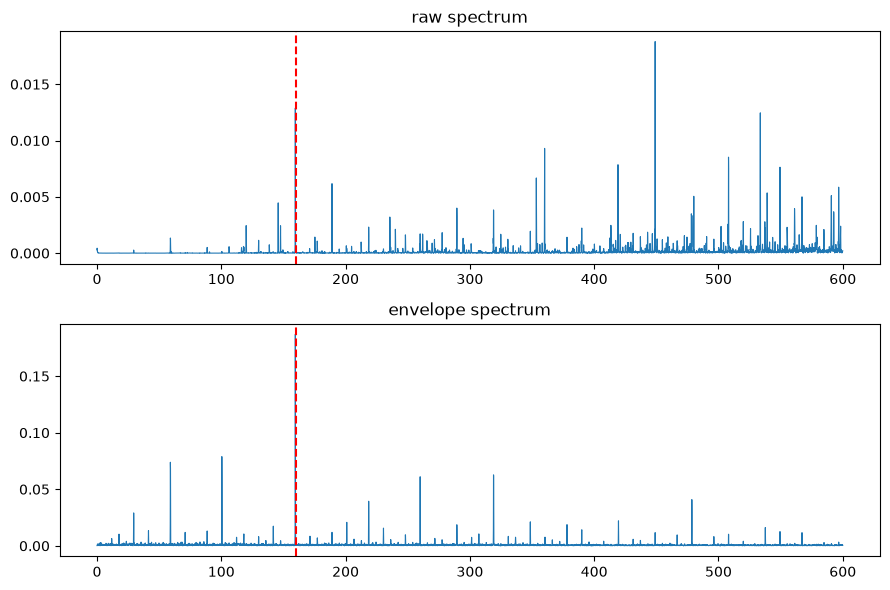

raw peak/floor at BPFI: 428.9  envelope: 272.6


In [8]:
rec, shaft, fe, me = env_of(106)
fr, mr = amplitude_spectrum(rec.signal, rec.fs)
f0 = MULT["BPFI"] * shaft
fig, ax = plt.subplots(2, 1, figsize=(9, 6))
for a, (f, m, t) in zip(ax, [(fr, mr, "raw spectrum"), (fe, me, "envelope spectrum")]):
    k = f < 600
    a.plot(f[k], m[k], lw=.8); a.axvline(f0, ls="--", c="r"); a.set_title(t)
plt.tight_layout(); plt.show()
print("raw peak/floor at BPFI:", round(peak_to_floor(fr, mr, f0), 1),
      " envelope:", round(peak_to_floor(fe, me, f0), 1))

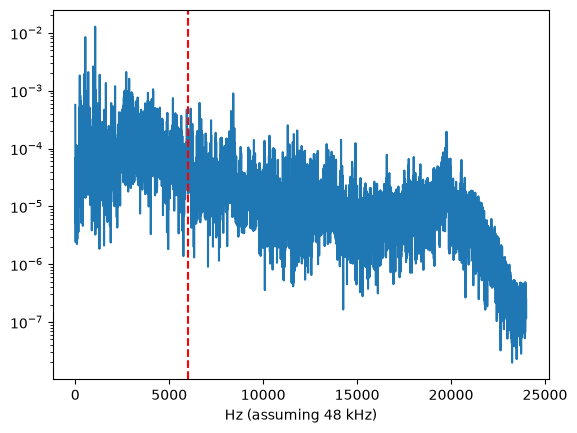

In [9]:
raw = load_cwru_file(CWRU_RAW / "normal" / "98.mat", 48000, target_fs=48000).signal
f, m = amplitude_spectrum(raw, 48000)
plt.semilogy(f[::20], m[::20]); plt.axvline(6000, c="r", ls="--"); plt.xlabel("Hz (assuming 48 kHz)")
plt.show()

In [10]:
tf = time_features(X.astype("float64"))
tab = pd.concat([info[["label", "load_hp"]], tf[["t_rms", "t_kurtosis", "t_crest"]]], axis=1)
tab.groupby(["label", "load_hp"]).mean().round(2).unstack("load_hp")

t_rms                   t_kurtosis                       \
load_hp              0     1     2     3          0      1      2      3   
label                                                                      
ball_0.007        0.14  0.14  0.15  0.15       2.96   2.96   2.83   2.89   
ball_0.014        0.15  0.14  0.14  0.13       9.02   7.14   7.11   8.15   
ball_0.021        0.13  0.12  0.11  0.12       4.07   4.22   3.26   3.09   
inner_race_0.007  0.29  0.29  0.30  0.31       5.40   5.54   5.56   5.28   
inner_race_0.014  0.20  0.16  0.16  0.18      22.02  21.31  21.24  17.88   
inner_race_0.021  0.52  0.44  0.49  0.45       7.39   7.63   7.98   8.31   
normal            0.07  0.06  0.06  0.06       2.77   2.97   2.96   3.05   
outer_race_0.007  0.67  0.59  0.57  0.58       7.63   7.58   7.85   7.96   
outer_race_0.014  0.10  0.09  0.10  0.09       3.01   2.93   3.01   3.44   
outer_race_0.021  0.58  0.56  0.57  0.56      20.08  20.61  21.52  21.33   

                 t_crest                    
load_hp                0     1     2     3  
label                                       
ball_0.007          3.54  3.51  3.38  3.48  
ball_0.014          6.43  5.93  6.12  6.32  
ball_0.021          4.41  4.43  3.81  3.63  
inner_race_0.007    5.12  4.91  4.74  4.46  
inner_race_0.014    8.62  9.03  8.97  8.72  
inner_race_0.021    6.00  5.85  5.69  6.07  
normal              3.42  3.57  3.64  3.72  
outer_race_0.007    4.90  4.96  4.99  5.08  
outer_race_0.014    3.60  3.57  3.62  4.03  
outer_race_0.021    8.49  8.61  8.77  8.57

In [11]:
import pandas as pd
from src.config import DATA_RAW

cm = DATA_RAW / "cmapss"
print((cm / "readme.txt").read_text(encoding="latin-1")[:1500])
for fd in ["FD001", "FD002", "FD003", "FD004"]:
    tr = pd.read_csv(cm / f"train_{fd}.txt", sep=r"\s+", header=None)
    te = pd.read_csv(cm / f"test_{fd}.txt", sep=r"\s+", header=None)
    rul = pd.read_csv(cm / f"RUL_{fd}.txt", sep=r"\s+", header=None)
    print(fd, "train", tr.shape, "engines", tr[0].nunique(),
          "| test", te.shape, "engines", te[0].nunique(), "| RUL rows", len(rul))
tr.head(3)

Data Set: FD001
Train trjectories: 100
Test trajectories: 100
Conditions: ONE (Sea Level)
Fault Modes: ONE (HPC Degradation)

Data Set: FD002
Train trjectories: 260
Test trajectories: 259
Conditions: SIX 
Fault Modes: ONE (HPC Degradation)

Data Set: FD003
Train trjectories: 100
Test trajectories: 100
Conditions: ONE (Sea Level)
Fault Modes: TWO (HPC Degradation, Fan Degradation)

Data Set: FD004
Train trjectories: 248
Test trajectories: 249
Conditions: SIX 
Fault Modes: TWO (HPC Degradation, Fan Degradation)



Experimental Scenario

Data sets consists of multiple multivariate time series. Each data set is further divided into training and test subsets. Each time series is from a different engine  i.e., the data can be considered to be from a fleet of engines of the same type. Each engine starts with different degrees of initial wear and manufacturing variation which is unknown to the user. This wear and variation is considered normal, i.e., it is not considered a fault condition. Th

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.0,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.0,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.0,10.48,6.4213


In [12]:
from src.cmapss import (load_cmapss, add_rul, ConditionScaler, N_CONDITIONS, SENSORS)
for fd in ["FD001", "FD004"]:
    train, test, rul_end = load_cmapss(fd)
    train = add_rul(train, cap=125)
    sc = ConditionScaler(N_CONDITIONS[fd]).fit(train)
    print(fd, "kept sensors:", len(sc.keep_), "dropped:", sorted(set(SENSORS) - set(sc.keep_)))
    if N_CONDITIONS[fd] > 1:
        print(sc._cond(train).value_counts().sort_index().to_dict())

FD001 kept sensors: 14 dropped: ['s1', 's10', 's16', 's18', 's19', 's5', 's6']
FD004 kept sensors: 16 dropped: ['s1', 's16', 's18', 's19', 's5']
{0: 15395, 1: 9224, 2: 9139, 3: 9091, 4: 9238, 5: 9162}


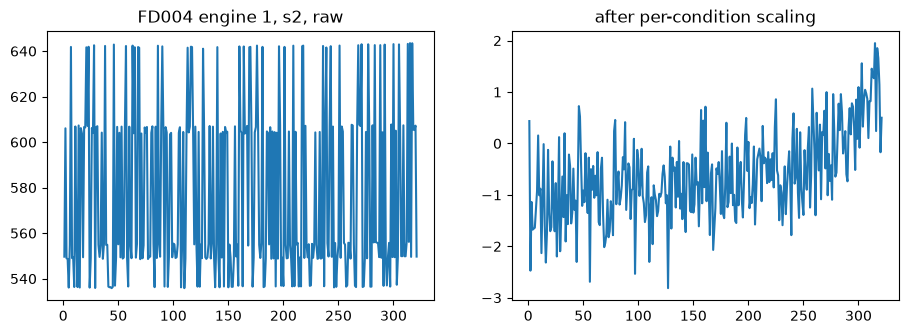

In [13]:
train, _, _ = load_cmapss("FD004"); train = add_rul(train)
sc = ConditionScaler(6).fit(train)
scaled = sc.transform(train)
g_raw, g_sc = train[train.unit == 1], scaled[scaled.unit == 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(g_raw.cycle, g_raw.s2); ax[0].set_title("FD004 engine 1, s2, raw")
ax[1].plot(g_sc.cycle, g_sc.s2); ax[1].set_title("after per-condition scaling")
plt.show()

In [14]:
train, _, _ = load_cmapss("FD004")
key = (train[["op1", "op2", "op3"]].round({"op1": 0, "op2": 2, "op3": 0}) + 0.0).astype(str).agg("/".join, axis=1)
print(key.value_counts())
sc = ConditionScaler(6).fit(train)
print(pd.crosstab(key, sc._cond(train)))

42.0/0.84/100.0    15395
0.0/0.0/100.0       9238
10.0/0.25/100.0     9224
35.0/0.84/100.0     9162
25.0/0.62/60.0      9139
20.0/0.7/100.0      9091
Name: count, dtype: int64
col_0                0     1     2     3     4     5
row_0                                               
0.0/0.0/100.0        0     0     0     0  9238     0
10.0/0.25/100.0      0  9224     0     0     0     0
20.0/0.7/100.0       0     0     0  9091     0     0
25.0/0.62/60.0       0     0  9139     0     0     0
35.0/0.84/100.0      0     0     0     0     0  9162
42.0/0.84/100.0  15395     0     0     0     0     0


In [15]:
train, test, rul_end = load_cmapss("FD001"); train = add_rul(train)
sc = ConditionScaler(1).fit(train)
rows = [(s, train[s].nunique(), round(train[s].corr(train["rul"], method="spearman"), 2)) for s in sc.keep_]
pd.DataFrame(rows, columns=["sensor", "n_unique", "spearman_vs_rul"]).sort_values("spearman_vs_rul", key=abs)


,sensor,n_unique,spearman_vs_rul
9,s14,6078,-0.21
5,s9,6403,-0.33
8,s13,56,-0.57
4,s8,53,-0.57
1,s3,3012,-0.61
0,s2,310,-0.63
11,s17,13,-0.64
12,s20,120,0.66
13,s21,4745,0.66
10,s15,1918,-0.67


In [16]:
def dominance(freqs, mag, f0, tol=0.03, lo=10, hi=600):
    inband = (freqs >= f0*(1-tol)) & (freqs <= f0*(1+tol))
    in_range = (freqs >= lo) & (freqs <= hi)
    return float(mag[inband].max() / mag[in_range & ~inband].max())

rows = []
for fid, d in [(106, "BPFI"), (131, "BPFO"), (119, "BSF")]:
    rec, shaft, fe, me = env_of(fid)
    fr, mr = amplitude_spectrum(rec.signal, rec.fs)
    f0 = MULT[d] * shaft
    rows.append({"file": fid, "defect": d,
                 "raw": round(dominance(fr, mr, f0), 2),
                 "envelope": round(dominance(fe, me, f0), 2)})
pd.DataFrame(rows)

,file,defect,raw,envelope
0,106,BPFI,0.69,2.37
1,131,BPFO,0.13,1.35
2,119,BSF,0.03,0.47


In [17]:
import numpy as np
from src.baselines import cwru_features, run_cwru_baselines, run_cmapss_baselines
F = cwru_features(X)
res_cwru = run_cwru_baselines(F, info)
res_cwru

,model,protocol,accuracy,macro_F1
0,LogisticRegression,random window split (leaky),1.000 +- 0.000,1.000 +- 0.000
1,LogisticRegression,leave-one-load-out (honest),0.960 +- 0.069,0.953 +- 0.082
2,DecisionTree,random window split (leaky),0.996 +- 0.001,0.996 +- 0.001
3,DecisionTree,leave-one-load-out (honest),0.912 +- 0.076,0.890 +- 0.100
4,RandomForest,random window split (leaky),1.000 +- 0.000,1.000 +- 0.000
5,RandomForest,leave-one-load-out (honest),0.996 +- 0.005,0.996 +- 0.004
6,XGBoost,random window split (leaky),0.999 +- 0.001,0.999 +- 0.001
7,XGBoost,leave-one-load-out (honest),0.941 +- 0.086,0.928 +- 0.107


In [18]:
res_cm = pd.concat([run_cmapss_baselines(fd) for fd in ["FD001", "FD002", "FD003", "FD004"]])
res_cm

,dataset,model,RMSE,MAE,NASA_score
0,FD001,LinearRegression,20.88,16.54,1726.3
1,FD001,DecisionTree,19.81,14.42,1255.9
2,FD001,RandomForest,19.84,13.51,1980.1
3,FD001,XGBoost,19.03,13.37,1383.4
0,FD002,LinearRegression,18.67,14.84,1985.2
1,FD002,DecisionTree,17.31,12.92,1729.0
2,FD002,RandomForest,15.95,12.15,1394.9
3,FD002,XGBoost,16.34,12.35,1946.8
0,FD003,LinearRegression,20.19,15.92,1389.0
1,FD003,DecisionTree,22.17,15.26,3403.9


In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from src.dataset import split_by_load
y = pd.factorize(info["label"], sort=True)[0]
names = sorted(info["label"].unique())
preds = np.empty_like(y)
for test_load in range(4):
    tr, _, te = split_by_load(info, test_load, None)
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
    preds[te] = rf.fit(F.to_numpy()[tr], y[tr]).predict(F.to_numpy()[te])
pd.DataFrame(confusion_matrix(y, preds), index=names, columns=names)

,ball_0.007,ball_0.014,ball_0.021,inner_race_0.007,inner_race_0.014,inner_race_0.021,normal,outer_race_0.007,outer_race_0.014,outer_race_0.021
ball_0.007,468,1,0,0,0,0,0,0,0,0
ball_0.014,7,458,5,0,1,0,0,0,0,0
ball_0.021,0,4,467,0,0,0,0,0,0,0
inner_race_0.007,0,0,0,472,0,0,0,0,0,0
inner_race_0.014,0,0,0,0,468,0,0,0,0,0
inner_race_0.021,0,0,0,0,0,470,0,0,0,0
normal,0,0,0,0,0,0,409,0,0,0
outer_race_0.007,0,0,0,0,0,0,0,471,0,0
outer_race_0.014,0,0,0,0,0,0,0,0,470,0
outer_race_0.021,0,0,0,0,0,0,0,0,0,472


{'rows': 2560, 'span_s': 0.099956, 'implied_fs_hz': 25601.3}
2803 snapshots; duration (h): 7.78 ; first predicting idx: 1374


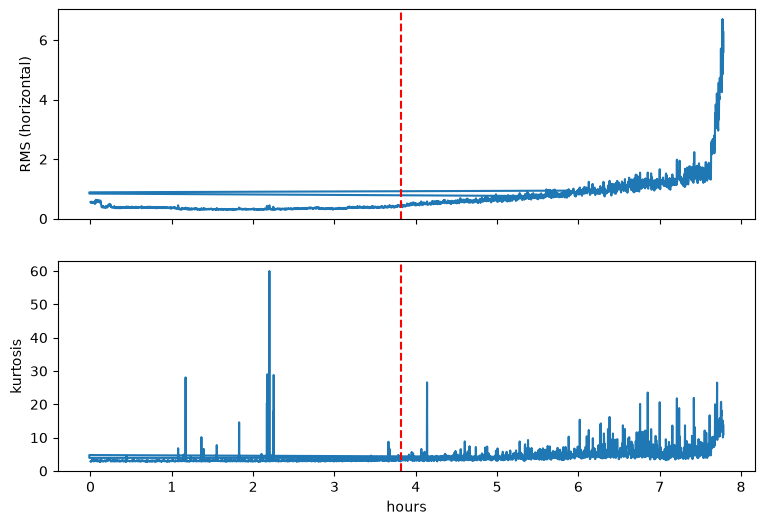

In [20]:
from src.femto import check_fs, bearing_features, add_rul, first_predicting_time, build_femto_features
from src.config import DATA_RAW
b11 = DATA_RAW / "femto" / "training_set" / "Bearing1_1"
print(check_fs(b11 / "acc_00001.csv"))
df = add_rul(bearing_features(b11))
fpt = first_predicting_time(df)
print(len(df), "snapshots; duration (h):", round(df.t.iloc[-1] / 3600, 2), "; first predicting idx:", fpt)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(df.t / 3600, df.rms_h); ax[0].set_ylabel("RMS (horizontal)")
ax[1].plot(df.t / 3600, df.kurt_h); ax[1].set_ylabel("kurtosis"); ax[1].set_xlabel("hours")
if fpt is not None:
    for a in ax:
        a.axvline(df.t[fpt] / 3600, c="r", ls="--")
plt.show()

In [21]:
feats = build_femto_features(sets=("training_set",))

training_set/Bearing1_1: 2803 snapshots
training_set/Bearing1_2: 871 snapshots
training_set/Bearing2_1: 911 snapshots
training_set/Bearing2_2: 797 snapshots
training_set/Bearing3_1: 515 snapshots
training_set/Bearing3_2: 1637 snapshots


In [22]:
rows = []
for s in ["training_set", "test_set", "validation_set"]:
    for folder in sorted((DATA_RAW / "femto" / s).glob("Bearing*")):
        rows.append({"set": s, "bearing": folder.name, "acc_files": sum(1 for _ in folder.glob("acc_*.csv"))})
pd.DataFrame(rows).pivot(index="bearing", columns="set", values="acc_files")

set,test_set,training_set,validation_set
bearing,,,
Bearing1_1,NaN,2803.0,NaN
Bearing1_2,NaN,871.0,NaN
Bearing1_3,1802.0,NaN,2375.0
Bearing1_4,1139.0,NaN,1428.0
Bearing1_5,2302.0,NaN,2463.0
Bearing1_6,2302.0,NaN,2448.0
Bearing1_7,1502.0,NaN,2259.0
Bearing2_1,NaN,911.0,NaN
Bearing2_2,NaN,797.0,NaN


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
y = pd.factorize(info["label"], sort=True)[0]
band_cols = [c for c in F.columns if c.startswith("band_")]
time_cols = [c for c in F.columns if c.startswith("t_")]
subsets = {"all": list(F.columns), "time only": time_cols,
           "bands+centroid only": band_cols + ["centroid"],
           "no top-4 bands": [c for c in F.columns if c not in band_cols[-4:]]}
for name, cols in subsets.items():
    accs = []
    for test_load in range(4):
        tr, _, te = split_by_load(info, test_load, None)
        rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42).fit(F[cols].to_numpy()[tr], y[tr])
        accs.append(accuracy_score(y[te], rf.predict(F[cols].to_numpy()[te])))
    print(f"{name:22s} acc {np.mean(accs):.3f} +- {np.std(accs):.3f}  per-load {np.round(accs, 3)}")

all                    acc 0.996 +- 0.005  per-load [0.988 1.    0.997 0.999]
time only              acc 0.941 +- 0.052  per-load [0.852 0.979 0.979 0.953]
bands+centroid only    acc 0.981 +- 0.027  per-load [0.935 1.    0.991 1.   ]
no top-4 bands         acc 0.982 +- 0.028  per-load [0.935 0.994 1.    1.   ]


In [26]:
df = add_rul(bearing_features(b11))
fpt = first_predicting_time(df, ref=(150, 600), smooth=5)
print(fpt, "->", round(fpt * 10 / 3600, 2), "h")

1363 -> 3.79 h


In [27]:
from src.config import DATA_RAW
b11 = DATA_RAW / "femto" / "training_set" / "Bearing1_1"

In [28]:
from src.femto import check_fs, bearing_features, add_rul, first_predicting_time
print(check_fs(b11 / "acc_00001.csv"))

{'rows': 2560, 'span_s': 0.099956, 'implied_fs_hz': 25601.3}


In [29]:
from sklearn.model_selection import GroupShuffleSplit
from src.cmapss import load_cmapss, add_rul, ConditionScaler, N_CONDITIONS, make_sequences

train, test, rul_end = load_cmapss("FD001"); train = add_rul(train)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, va_idx = next(gss.split(train, groups=train["unit"]))
tr_units, va_units = set(train.iloc[tr_idx].unit), set(train.iloc[va_idx].unit)
assert not (tr_units & va_units)
print(len(tr_units), "train engines,", len(va_units), "validation engines")

sc = ConditionScaler(N_CONDITIONS["FD001"]).fit(train.iloc[tr_idx])   # fit on train engines only
tr_s = sc.transform(train).assign(rul=train["rul"])
Xs, ys, us = make_sequences(tr_s, sc.keep_, seq_len=30)
print(Xs.shape, ys.shape, "NaN labels:", int(np.isnan(ys).sum()))

80 train engines, 20 validation engines
(17731, 30, 14) (17731,) NaN labels: 0


In [3]:
from src import femto
from src.config import DATA_RAW

b11 = DATA_RAW / "femto" / "training_set" / "Bearing1_1"
df = femto.add_rul(femto.bearing_features(b11))
d = df["t"].diff()
print(d.describe().round(2))
print(df.loc[(d < 5) | (d > 15), ["idx", "t"]].head(15))

count     2802.00
mean        10.00
std        568.02
min     -21242.20
25%         10.00
50%         10.00
75%         10.00
max      21272.20
Name: t, dtype: float64
       idx             t
2120  2120    -52.200004
2121  2121    -52.200004
2122  2122  21220.000000


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import decimate
from src.utils import set_seed
from src.config import CWRU_RAW, SEED
from src.cwru_meta import build_metadata
from src.data_loader import load_cwru_file
from src.cwru_reference import MULT
from src.signal_proc import (WIN_LEN, time_features, amplitude_spectrum,
                             envelope_spectrum, peak_to_floor, spectrogram_db)

set_seed(SEED)
meta = build_metadata().set_index("file_id")

def load(fid):
    r = meta.loc[fid]
    return load_cwru_file(CWRU_RAW / r.relpath, int(r.fs_native))

def env_of(fid):
    rec = load(fid)
    rpm = rec.rpm or meta.loc[fid, "nominal_rpm"]
    shaft = rpm / 60
    fe, me = envelope_spectrum(rec.signal, rec.fs)
    return rec, shaft, fe, me

In [7]:
for d_name in ["BPFI", "BPFO", "BSF"]:
    rec, shaft, _, _ = env_of(106)
    print(d_name, round(MULT[d_name] * shaft * WIN_LEN / 12000, 1), "events per window; shaft turns:",
          round(shaft * WIN_LEN / 12000, 1))

BPFI 27.3 events per window; shaft turns: 5.0
BPFO 18.1 events per window; shaft turns: 5.0
BSF 23.8 events per window; shaft turns: 5.0


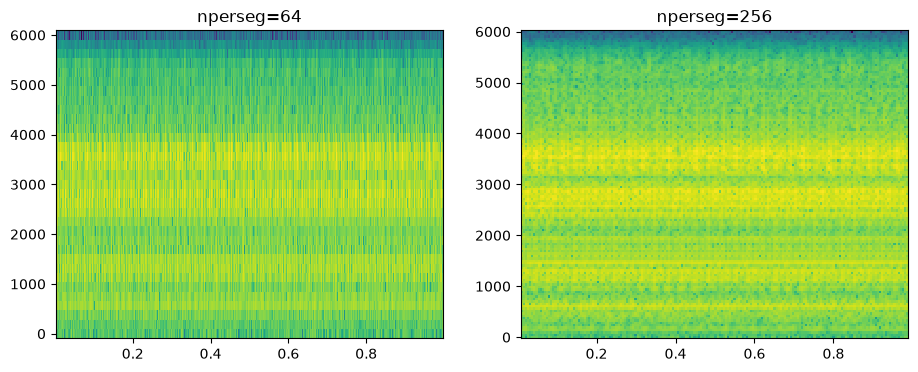

In [6]:
rec, shaft, fe, me = env_of(106)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax_, nps in zip(axes, [64, 256]):
    f, t, S = spectrogram_db(rec.signal[:12000], rec.fs, nperseg=nps)
    ax_.pcolormesh(t, f, S, shading="auto"); ax_.set_title(f"nperseg={nps}")
plt.show()

In [8]:
fs = 12000
t = np.arange(2048) / fs
x = np.sin(2*np.pi*1000.5*t)                 # tone between FFT bins: worst case for leakage
rect = np.abs(np.fft.rfft(x - x.mean())) * 2 / len(x)
f, hann_mag = amplitude_spectrum(x, fs)
far = (f > 2000)
print("rectangular: peak", rect.max().round(3), "| level far from the tone", rect[far].mean().round(5))
print("Hann:        peak", hann_mag.max().round(3), "| level far from the tone", hann_mag[far].mean().round(6))

rectangular: peak 0.902 | level far from the tone 0.00052
Hann:        peak 0.961 | level far from the tone 0.0


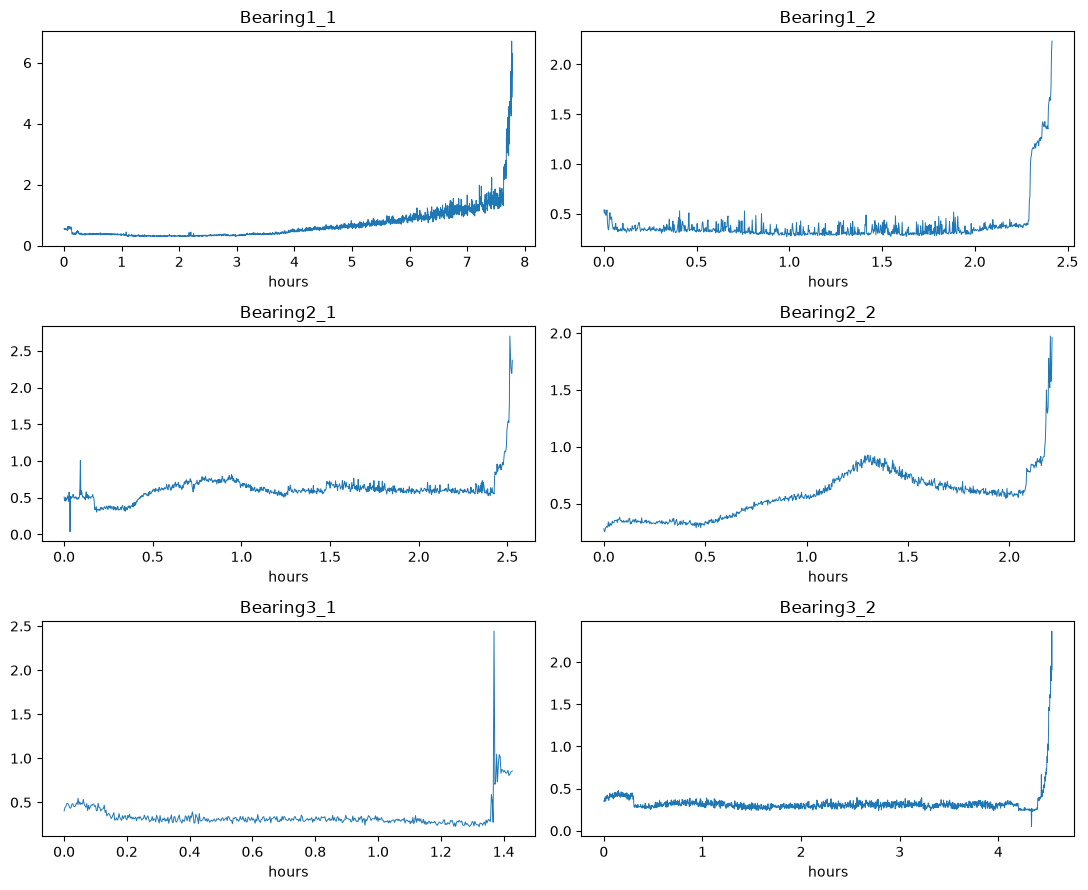

In [9]:
from src.config import DATA_PROCESSED
feats = pd.read_csv(DATA_PROCESSED / "femto_features.csv")
fig, axes = plt.subplots(3, 2, figsize=(11, 9))
for ax, (name, g) in zip(axes.ravel(), feats.groupby("bearing")):
    ax.plot(g["idx"] * 10 / 3600, g["rms_h"], lw=0.7)
    ax.set_title(name); ax.set_xlabel("hours")
plt.tight_layout(); plt.show()

In [10]:
from src.femto import build_femto_features
val = build_femto_features(sets=("validation_set",), save=False)
val.to_csv(DATA_PROCESSED / "femto_features_validation.csv", index=False)
print(val.groupby("bearing").size())

validation_set/Bearing1_3: 2375 snapshots
validation_set/Bearing1_4: 1428 snapshots
validation_set/Bearing1_5: 2463 snapshots
validation_set/Bearing1_6: 2448 snapshots
validation_set/Bearing1_7: 2259 snapshots
validation_set/Bearing2_3: 1955 snapshots
validation_set/Bearing2_4: 751 snapshots
validation_set/Bearing2_5: 2311 snapshots
validation_set/Bearing2_6: 701 snapshots
validation_set/Bearing2_7: 230 snapshots
validation_set/Bearing3_3: 434 snapshots
bearing
Bearing1_3    2375
Bearing1_4    1428
Bearing1_5    2463
Bearing1_6    2448
Bearing1_7    2259
Bearing2_3    1955
Bearing2_4     751
Bearing2_5    2311
Bearing2_6     701
Bearing2_7     230
Bearing3_3     434
dtype: int64
